In [ ]:
# Why do we need files?


RAM (random access memory) is volatile memory. We need persistent storage. 

We will use files, stored in laptop hard disk.

### 0. Opening a file

In [ ]:
my_file = open('numbers.txt', 'r')

# some code here

print(my_file.closed)
my_file.close()
print(my_file.closed)

In [ ]:
with open('numbers.txt', 'r') as my_file:
    # some code here
    print("Inside with block: ", my_file.closed)

print("Outside with block:", my_file.closed)

### 1. Reading a file line per line

In [ ]:
with open('schools.txt','r') as input_file:
    for line in input_file:
        print(line)

In [ ]:
with open('schools.txt','r') as input_file:
    for line in input_file:
        print('(' + line + ')')

In [ ]:
with open('schools.txt','r') as input_file:
    for line in input_file:
        print(line , len(line))
    

In [12]:
s = 'abc\n123'
print(s, len(s))

abc
123 7


### rstrip()

In [ ]:
# Solution to get rid of '\n'
# note we could also use slicing line = line[:-1]
with open('schools.txt','r') as input_file:
    for line in input_file:
        line = line.rstrip('\n')
        print(line )

In [1]:
# how to remove characters on the right or on the left
s = '***abc*1235*4**'
print(s.rstrip('*'))

***abc*1235*4


In [2]:
s = '***$*abc*$*123***'
print(s.lstrip('*$'))

abc*$*123***


In [3]:
s = '**$*abc*$123***'
print(s.strip('*$'))

abc*$123


In [34]:
# if you need to read the file twice:

with open('schools.txt','r') as input_file:
    print("\nFirst time:")
    for line in input_file:
        line = line.rstrip('\n')
        print(line)

    print("\nSecond time:")
    for line in input_file:
        print("hello")
        line = line.rstrip('\n')
        print(line)


First time:
SCIS
LKCSB
SOSS

Second time:


Why the file is not read the second time???????

Let's try that:

In [35]:
# if you need to read the file twice, you need to re-open the file
print("\nFirst time:")
with open('schools.txt','r') as input_file:
    for line in input_file:
        line = line.rstrip('\n')
        print(line)

print("\nSecond time:")
with open('schools.txt','r') as input_file:
    for line in input_file:
        line = line.rstrip('\n')
        print(line)


First time:
SCIS
LKCSB
SOSS

Second time:
SCIS
LKCSB
SOSS


In [ ]:
### *****************************************************
### But a file should NOT be read twice preferably!!!!
### *****************************************************

One way to solve that is to read the file once and to store the content into a list (or list of tuples).

Consecutively, each time we need data from the file we can get it from the list.

In [4]:
a_list = []
with open('schools.txt','r') as input_file:
    for line in input_file:
        line = line.rstrip('\n')
        a_list.append(line)

print(a_list)

['SCIS', 'LKCSB', 'SOSS']


### What if the file starts by a header???

![Screenshot 2026-10-19 at 4.00.58 PM.png](<attachment:Screenshot 2026-10-19 at 4.00.58 PM.png>)
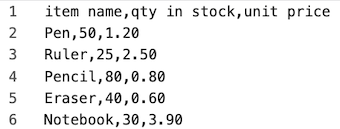

In [38]:
with open('inventory.txt','r') as input_file:
    
    # reading the first line of the file separately
    header = input_file.readline().rstrip('\n')
    print("Header:", header)

    for line in input_file:
        line = line.rstrip('\n')
        columns = line.split(',')
        print(columns)

Header: item name,qty in stock,unit price
['Pen', '50', '1.20']
['Ruler', '25', '2.50']
['Pencil', '80', '0.80']
['Eraser', '40', '0.60']
['Notebook', '30', '3.90']


### 2. Reading a file with columns 

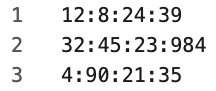

### split()

In [6]:
with open('numbers.txt','r') as input_file:
    for line in input_file:
        line = line.rstrip('\n')
        print(line, type(line))

        columns = line.split(':')

        print(columns)
        print()

12:8:24:39 <class 'str'>
['12', '8', '24', '39']

32:45:23:984 <class 'str'>
['32', '45', '23', '984']

4:90:21:35 <class 'str'>
['4', '90', '21', '35']



Notice that the `split()` method changes the string into a list of `strings` (not a list of `integers`)!!!

In [5]:
a_list = []
with open('numbers.txt','r') as input_file:
    for line in input_file:
        line = line.rstrip('\n')
        columns = line.split(':')
        qty_1 = int(columns[0])
        qty_2 = int(columns[1])
        qty_3 = int(columns[2])
        qty_4 = int(columns[3])
        a_list.append( (qty_1, qty_2, qty_3, qty_4) )

print(a_list)

[(12, 8, 24, 39), (32, 45, 23, 984), (4, 90, 21, 35)]


#### Other example

Assume we want to retrieve all the movies produced in 2014 only.

![Screenshot 2026-10-19 at 3.59.28 PM.png](<attachment:Screenshot 2026-10-19 at 3.59.28 PM.png>)
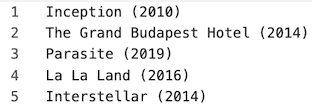

In [ ]:
with open('movies.txt', 'r') as my_file:
    for line in my_file:
        if "2014" in line:
            line = line.rstrip('\n')
            
            print(line)

The Grand Budapest Hotel (2014)
Interstellar (2014)


In [7]:
with open('movies.txt', 'r') as my_file:
    for line in my_file:
        line = line.rstrip('\n')
        movies_list = line.split('(')
        print(movies_list)


['Inception ', '2010)']
['The Grand Budapest Hotel ', '2014)']
['Parasite ', '2019)']
['La La Land ', '2016)']
['Interstellar ', '2014)']


In [8]:
with open('movies.txt', 'r') as my_file:
    for line in my_file:
        line = line.rstrip('\n')
        movies_list = line.split('(')
        date = movies_list[-1][:-1]
        if date == '2014':
            print(movies_list[0])   # name of the movie

The Grand Budapest Hotel 
Interstellar 


### 3. Writing to a file

In [16]:
with open('my_output.txt', 'w') as output_file:
    output_file.write('55')
    output_file.write('This is week 10.')
    output_file.write('We are learning file handling!')

In [17]:
with open('my_output.txt', 'w') as output_file:
    output_file.write('55' + '\n')
    output_file.write('This is week 10.' + '\n')
    output_file.write('We are learning file handling!'+ '\n')

### ICEs